In [1]:
# Importación de librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
sns.set_theme(style="whitegrid")

print("Librerías importadas correctamente")

Librerías importadas correctamente


In [2]:
# Cargar el dataset

df = pd.read_csv('train_u6lujuX_CVtuZ9i.csv')

# Mostrar los primeros registros
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


### 1. Comprensión del problema

El proyecto consiste en desarrollar un modelo de Machine Learning capaz de predecir si una solicitud de préstamo será aprobada o rechazada por una entidad financiera.

Para realizar esta predicción, se analizarán diferentes características de los solicitantes, como sus ingresos, historial crediticio, nivel educativo, estado civil y monto del préstamo solicitado.

El propósito es identificar patrones en los datos que permitan construir un modelo predictivo que apoye los procesos de evaluación y toma de decisiones de las entidades financieras.

**Variable objetivo (Target): Loan_Status**

Es la variable que el modelo intentará predecir. Sus valores indican si una solicitud de préstamo fue aprobada (Y) o rechazada (N).

In [3]:
# Dimensiones del dataset

print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

Número de filas: 614
Número de columnas: 13


In [4]:
# Información general del dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [5]:
# Estadísticas descriptivas

df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [6]:
# Identificación de valores faltantes

print("Valores faltantes por variable:")
print(df.isnull().sum())

Valores faltantes por variable:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [7]:
# Porcentaje de valores faltantes

porcentaje_nulos = (df.isnull().sum() / len(df)) * 100

print(porcentaje_nulos.sort_values(ascending=False))

Credit_History       8.143322
Self_Employed        5.211726
LoanAmount           3.583062
Dependents           2.442997
Loan_Amount_Term     2.280130
Gender               2.117264
Married              0.488599
Education            0.000000
Loan_ID              0.000000
CoapplicantIncome    0.000000
ApplicantIncome      0.000000
Property_Area        0.000000
Loan_Status          0.000000
dtype: float64


In [8]:
# Identificar variables numéricas

numericas = df.select_dtypes(include=['int64', 'float64']).columns

print("Variables numéricas:")
print(list(numericas))

# Identificar variables categóricas

categoricas = df.select_dtypes(include=['object']).columns

print("\nVariables categóricas:")
print(list(categoricas))

Variables numéricas:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Variables categóricas:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Loan_Status']


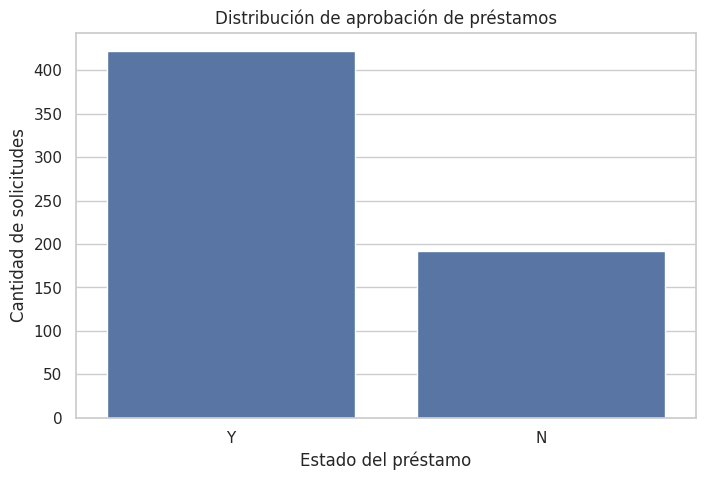

In [9]:
# Distribución de aprobación de préstamos

plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Loan_Status')

plt.title('Distribución de aprobación de préstamos')
plt.xlabel('Estado del préstamo')
plt.ylabel('Cantidad de solicitudes')

plt.show()

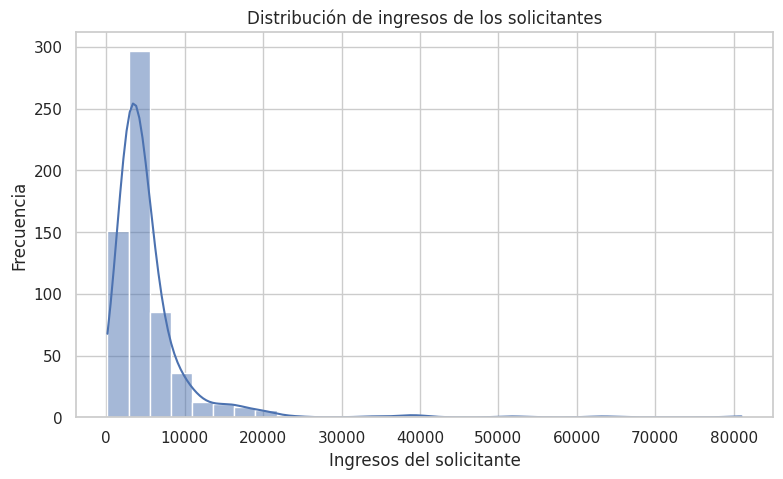

In [10]:
# Distribución de ingresos de los solicitantes

plt.figure(figsize=(9,5))

sns.histplot(df['ApplicantIncome'], bins=30, kde=True)

plt.title('Distribución de ingresos de los solicitantes')
plt.xlabel('Ingresos del solicitante')
plt.ylabel('Frecuencia')

plt.show()

In [12]:
# Distribución de la variable objetivo

print("Cantidad de solicitudes por categoría:")
print(df['Loan_Status'].value_counts())

print("\nPorcentaje de solicitudes:")
print(df['Loan_Status'].value_counts(normalize=True) * 100)

Cantidad de solicitudes por categoría:
Loan_Status
Y    422
N    192
Name: count, dtype: int64

Porcentaje de solicitudes:
Loan_Status
Y    68.729642
N    31.270358
Name: proportion, dtype: float64


In [13]:
# Identificación de registros duplicados

print("Cantidad de registros duplicados:", df.duplicated().sum())

Cantidad de registros duplicados: 0


In [14]:
# Eliminar identificador del préstamo

df = df.drop(columns=['Loan_ID'])

print("Columna Loan_ID eliminada correctamente")
print("Dimensiones actuales:", df.shape)

Columna Loan_ID eliminada correctamente
Dimensiones actuales: (614, 12)


### Resultados de la limpieza inicial

Se realizó una comprobación de la variable objetivo Loan_Status, identificando 422 solicitudes aprobadas (68.73 %) y 192 solicitudes rechazadas (31.27 %).

Se verificó que el conjunto de datos no contiene registros duplicados.

Adicionalmente, se eliminó la columna Loan_ID, debido a que funciona únicamente como identificador de cada solicitud y no aporta información predictiva relevante.

Después de esta operación, el conjunto de datos quedó conformado por 614 registros y 12 variables.

In [15]:
# Separación de variables predictoras y variable objetivo

X = df.drop('Loan_Status', axis=1)

y = df['Loan_Status']

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (614, 11)
Dimensiones de y: (614,)


In [16]:
# Importar herramienta para dividir los datos

from sklearn.model_selection import train_test_split

# División 80/20

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

print("\nRegistros de entrenamiento:", len(y_train))
print("Registros de prueba:", len(y_test))

Datos de entrenamiento: (491, 11)
Datos de prueba: (123, 11)

Registros de entrenamiento: 491
Registros de prueba: 123


| Conjunto | Registros | Porcentaje |
|---|---:|---:|
| Entrenamiento | 491 | 80 % |
| Prueba | 123 | 20 % |
| **Total** | **614** | **100 %** |

In [17]:
# Identificar variables numéricas y categóricas

numericas = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

categoricas = X_train.select_dtypes(include=['object']).columns.tolist()

print("Variables numéricas:")
print(numericas)

print("\nVariables categóricas:")
print(categoricas)

Variables numéricas:
['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

Variables categóricas:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


In [18]:
# Importar herramientas de preparación de datos

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Tratamiento de variables numéricas

transformador_numerico = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median'))
])

# Tratamiento de variables categóricas

transformador_categorico = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('codificador', OneHotEncoder(handle_unknown='ignore'))
])

print("Transformadores preparados correctamente")

Transformadores preparados correctamente


In [19]:
# Combinar los transformadores

preprocesador = ColumnTransformer(transformers=[
    ('numericas', transformador_numerico, numericas),
    ('categoricas', transformador_categorico, categoricas)
])

# Ajustar con entrenamiento y transformar ambos conjuntos

X_train_procesado = preprocesador.fit_transform(X_train)

X_test_procesado = preprocesador.transform(X_test)

print("Datos de entrenamiento procesados:", X_train_procesado.shape)

print("Datos de prueba procesados:", X_test_procesado.shape)

Datos de entrenamiento procesados: (491, 20)
Datos de prueba procesados: (123, 20)


In [20]:
# Importar modelo de regresión logística

from sklearn.linear_model import LogisticRegression

# Crear el modelo

modelo_logistico = LogisticRegression(max_iter=1000, random_state=42)

# Entrenar el modelo

modelo_logistico.fit(X_train_procesado, y_train)

print("Modelo de Regresión Logística entrenado correctamente")

Modelo de Regresión Logística entrenado correctamente


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [21]:
# Importar modelo Random Forest

from sklearn.ensemble import RandomForestClassifier

# Crear el modelo

modelo_random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Entrenar el modelo

modelo_random_forest.fit(X_train_procesado, y_train)

print("Modelo Random Forest entrenado correctamente")

Modelo Random Forest entrenado correctamente


In [22]:
# Predicciones de Regresión Logística

predicciones_logistica = modelo_logistico.predict(X_test_procesado)

# Predicciones de Random Forest

predicciones_random_forest = modelo_random_forest.predict(X_test_procesado)

print("Primeras predicciones de Regresión Logística:")
print(predicciones_logistica[:10])

print("\nPrimeras predicciones de Random Forest:")
print(predicciones_random_forest[:10])

Primeras predicciones de Regresión Logística:
['N' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y']

Primeras predicciones de Random Forest:
['N' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'Y' 'N' 'Y']


| Predicción | Regresión logística | Random Forest |
|---|---|---|
| 1 | N | N |
| 2 | Y | Y |
| 3 | Y | Y |
| 4 | Y | Y |
| 5 | Y | Y |
| 6 | Y | Y |
| 7 | Y | Y |
| 8 | Y | Y |
| 9 | Y | N |
| 10 | Y | Y |

In [23]:
# Importar métricas de evaluación

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Métricas de evaluación importadas correctamente")

Métricas de evaluación importadas correctamente


In [24]:
# Evaluación de Regresión Logística

print("EVALUACIÓN - REGRESIÓN LOGÍSTICA")

print("Accuracy:", accuracy_score(y_test, predicciones_logistica))

print("Precision:", precision_score(y_test, predicciones_logistica, pos_label='Y'))

print("Recall:", recall_score(y_test, predicciones_logistica, pos_label='Y'))

print("F1-score:", f1_score(y_test, predicciones_logistica, pos_label='Y'))

EVALUACIÓN - REGRESIÓN LOGÍSTICA
Accuracy: 0.8617886178861789
Precision: 0.84
Recall: 0.9882352941176471
F1-score: 0.9081081081081082


In [25]:
# Evaluación de Random Forest

print("EVALUACIÓN - RANDOM FOREST")

print("Accuracy:", accuracy_score(y_test, predicciones_random_forest))

print("Precision:", precision_score(y_test, predicciones_random_forest, pos_label='Y'))

print("Recall:", recall_score(y_test, predicciones_random_forest, pos_label='Y'))

print("F1-score:", f1_score(y_test, predicciones_random_forest, pos_label='Y'))

EVALUACIÓN - RANDOM FOREST
Accuracy: 0.8211382113821138
Precision: 0.8461538461538461
Recall: 0.9058823529411765
F1-score: 0.875


| Métrica | ¿Qué evalúa? |
|---|---|
| Accuracy | Porcentaje de predicciones correctas. |
| Precision | Qué proporción de los préstamos predichos como aprobados realmente fueron aprobados. |
| Recall | Qué proporción de los préstamos aprobados logró identificar el modelo. |
| F1-score | Equilibrio entre Precision y Recall. |

| Métrica | Regresión logística | Random Forest |
|---|---:|---:|
| Accuracy | 86.18 % | 82.11 % |
| Precision | 84.00 % | 80.85 % |
| Recall | 98.82 % | 90.59 % |
| F1-score | 90.81 % | 87.50 % |

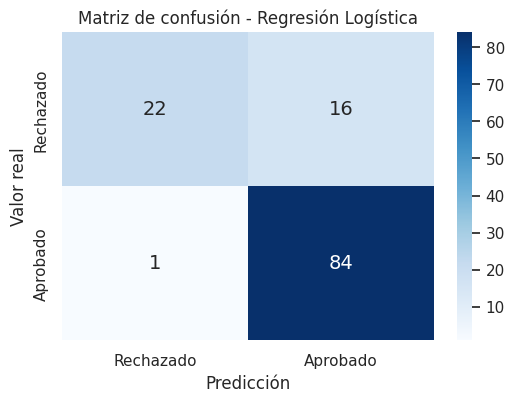

In [26]:
cm_logistica = confusion_matrix(
    y_test, predicciones_logistica, labels=['N', 'Y']
)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm_logistica,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Rechazado', 'Aprobado'],
    yticklabels=['Rechazado', 'Aprobado'],
    annot_kws={'size': 14}
)

plt.title('Matriz de confusión - Regresión Logística')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()

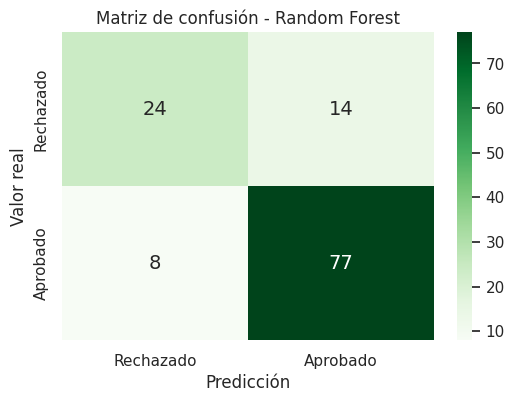

In [27]:
cm_random = confusion_matrix(
    y_test, predicciones_random_forest, labels=['N', 'Y']
)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm_random,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Rechazado', 'Aprobado'],
    yticklabels=['Rechazado', 'Aprobado'],
    annot_kws={'size': 14}
)

plt.title('Matriz de confusión - Random Forest')
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.show()

In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluación de Regresión Logística
print("REGRESIÓN LOGÍSTICA")
print("Accuracy:", round(accuracy_score(y_test, predicciones_logistica), 4))
print("Precision:", round(precision_score(y_test, predicciones_logistica, pos_label='Y'), 4))
print("Recall:", round(recall_score(y_test, predicciones_logistica, pos_label='Y'), 4))
print("F1-score:", round(f1_score(y_test, predicciones_logistica, pos_label='Y'), 4))

print("\n-----------------------------\n")

# Evaluación de Random Forest
print("RANDOM FOREST")
print("Accuracy:", round(accuracy_score(y_test, predicciones_random_forest), 4))
print("Precision:", round(precision_score(y_test, predicciones_random_forest, pos_label='Y'), 4))
print("Recall:", round(recall_score(y_test, predicciones_random_forest, pos_label='Y'), 4))
print("F1-score:", round(f1_score(y_test, predicciones_random_forest, pos_label='Y'), 4))

REGRESIÓN LOGÍSTICA
Accuracy: 0.8618
Precision: 0.84
Recall: 0.9882
F1-score: 0.9081

-----------------------------

RANDOM FOREST
Accuracy: 0.8211
Precision: 0.8462
Recall: 0.9059
F1-score: 0.875


| Métrica | Regresión Logística | Random Forest |
|---|---:|---:|
| Accuracy | 86,18 % | 82,11 % |
| Precision | 84,00 % | 84,62 % |
| Recall | 98,82 % | 90,59 % |
| F1-score | 90,81 % | 87,50 % |

IMPORTANCIA DE LAS VARIABLES


,0
numericas__Credit_History,0.215610
numericas__ApplicantIncome,0.205854
numericas__LoanAmount,0.181690
numericas__CoapplicantIncome,0.108519
numericas__Loan_Amount_Term,0.044667
categoricas__Property_Area_Semiurban,0.023836
categoricas__Dependents_0,0.020921
categoricas__Married_No,0.017801
categoricas__Education_Graduate,0.017623
categoricas__Dependents_1,0.017606


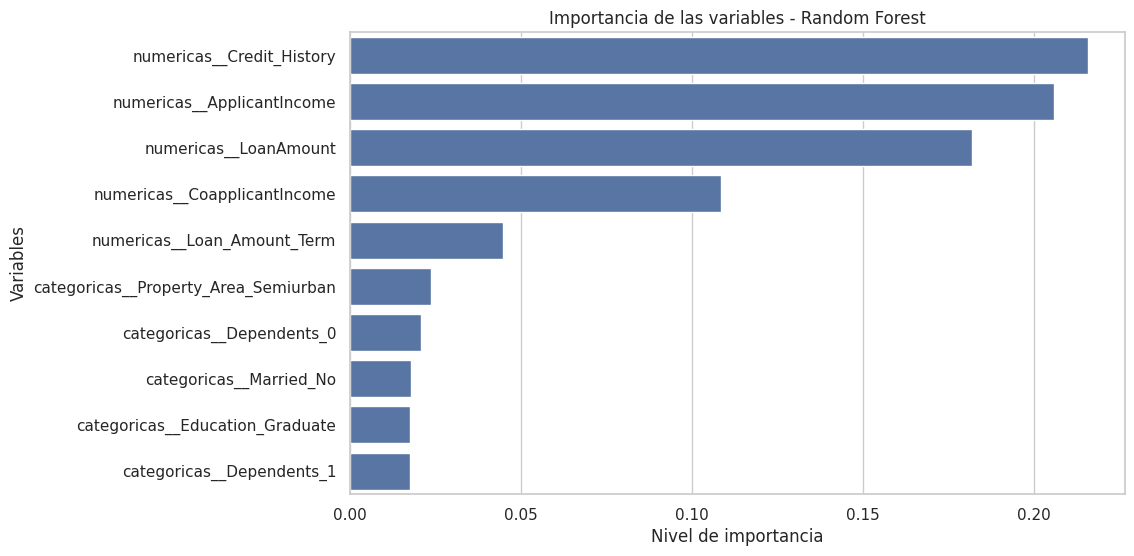

In [29]:
# Importancia de las variables en Random Forest

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importancias = pd.Series(
    modelo_random_forest.feature_importances_,
    index=preprocesador.get_feature_names_out()
).sort_values(ascending=False)

print("IMPORTANCIA DE LAS VARIABLES")
display(importancias.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=importancias.head(10).values,
    y=importancias.head(10).index
)

plt.title('Importancia de las variables - Random Forest')
plt.xlabel('Nivel de importancia')
plt.ylabel('Variables')
plt.show()

IMPORTANCIA DE LAS VARIABLES


,Importancia
Variable original,
Credit_History,0.215610
ApplicantIncome,0.205854
LoanAmount,0.181690
CoapplicantIncome,0.108519
Dependents,0.065522
Property_Area,0.056267
Loan_Amount_Term,0.044667
Education,0.035106
Married,0.031404


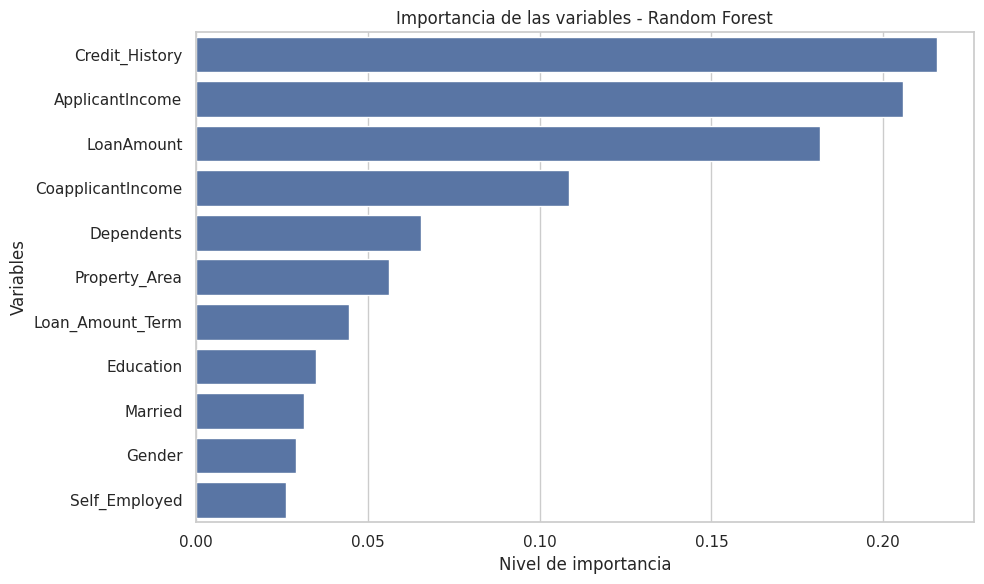

In [30]:
# Identificar la importancia de las variables

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Obtener nombres de las variables procesadas
nombres_variables = preprocesador.get_feature_names_out()

# Obtener importancia calculada por Random Forest
importancias = modelo_random_forest.feature_importances_

# Crear tabla de importancia
tabla_importancias = pd.DataFrame({
    'Variable': nombres_variables,
    'Importancia': importancias
})

# Agrupar las variables categóricas por su variable original
def obtener_variable_original(nombre):
    nombre = nombre.replace('numericas__', '')
    nombre = nombre.replace('categoricas__', '')

    for variable in categoricas:
        if nombre.startswith(variable + '_'):
            return variable

    return nombre

tabla_importancias['Variable original'] = (
    tabla_importancias['Variable'].apply(obtener_variable_original)
)

# Sumar importancia de las variables codificadas
importancia_agrupada = (
    tabla_importancias.groupby('Variable original')['Importancia']
    .sum()
    .sort_values(ascending=False)
)

print("IMPORTANCIA DE LAS VARIABLES")
display(importancia_agrupada.to_frame())

# Gráfico
plt.figure(figsize=(10, 6))

sns.barplot(
    x=importancia_agrupada.values,
    y=importancia_agrupada.index
)

plt.title('Importancia de las variables - Random Forest')
plt.xlabel('Nivel de importancia')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()

### 1. ¿Qué tan bueno es el modelo?

Los resultados obtenidos muestran que ambos modelos presentan un buen desempeño en la predicción de aprobación de préstamos.

La Regresión Logística obtuvo un Accuracy del 86,18 %, una Precision del 84 %, un Recall del 98,82 % y un F1-score del 90,81 %.

Por su parte, Random Forest obtuvo un Accuracy del 82,11 %, una Precision del 84,62 %, un Recall del 90,59 % y un F1-score del 87,50 %.

Al comparar los resultados, se observa que la Regresión Logística presenta el mejor rendimiento general. Por esta razón, se considera el modelo más adecuado entre los dos evaluados para este ejercicio.

Sin embargo, ambos modelos presentan dificultades para identificar correctamente algunas solicitudes rechazadas, por lo que todavía existe oportunidad de mejora.

### 2. ¿Qué variable parece influir más en la predicción?

De acuerdo con el gráfico de importancia de variables generado mediante Random Forest, la variable que más influye en las predicciones es Credit_History (historial crediticio).

En segundo lugar se encuentra ApplicantIncome (ingresos del solicitante), seguida de LoanAmount (monto del préstamo).

Estos resultados indican que el historial crediticio y la capacidad económica del solicitante son factores importantes para la clasificación de las solicitudes de crédito.

### Conclusiones

Durante el desarrollo de este taller se aplicaron diferentes técnicas de Machine Learning para solucionar un problema de clasificación relacionado con la aprobación de préstamos bancarios.

Se realizó un proceso de exploración, limpieza y preparación de datos, identificando variables numéricas y categóricas, tratando valores faltantes y transformando la información para su utilización en los modelos predictivos.

Posteriormente, se entrenaron dos algoritmos de clasificación: Regresión Logística y Random Forest, evaluando su rendimiento mediante las métricas Accuracy, Precision, Recall y F1-score, además de las matrices de confusión.

Los resultados permitieron identificar que la Regresión Logística obtuvo el mejor desempeño general, alcanzando una exactitud del 86,18 %.

Finalmente, mediante el análisis de importancia de variables se identificó que el historial crediticio es el factor con mayor influencia en las predicciones, seguido de los ingresos del solicitante y el monto del préstamo.

Este ejercicio permitió comprender cómo Machine Learning puede contribuir al análisis de información y a la toma de decisiones en el sector financiero.